# ML Kernel Roofline Analysis

Compare PyTorch baselines with custom Metal kernels. The Roofline view focuses on GEMM and fused multiply-add so that the effect of tiling and fusion stays readable. Traffic values are model-based estimates, not hardware-counter measurements. Naive GEMM points above the 200 GB/s reference can reflect GPU cache hits, not DRAM bandwidth beyond the published limit.

In [1]:
from pathlib import Path
import math
import pandas as pd
import matplotlib.pyplot as plt

csv_path = Path('../results/optimization_comparison.csv')
df = pd.read_csv(csv_path)
df.head()

,operation,size,device,precision,variant,median_ms,operations,gflops,modeled_bytes,estimated_gb_per_s,arithmetic_intensity,max_abs_error
0,fused_mul_add,65536,mps,fp32,metal_fused,0.150396,131072,0.871513,1048576,6.972100,0.125000,1.192093e-07
1,fused_mul_add,65536,mps,fp32,torch_eager,0.446187,131072,0.293760,1572864,3.525124,0.083333,0.000000e+00
2,fused_mul_add,262144,mps,fp32,metal_fused,0.162083,524288,3.234678,4194304,25.877427,0.125000,1.192093e-07
3,fused_mul_add,262144,mps,fp32,torch_eager,0.483729,524288,1.083847,6291456,13.006160,0.083333,0.000000e+00
4,fused_mul_add,1048576,mps,fp32,metal_fused,0.197480,2097152,10.619593,16777216,84.956747,0.125000,1.192093e-07


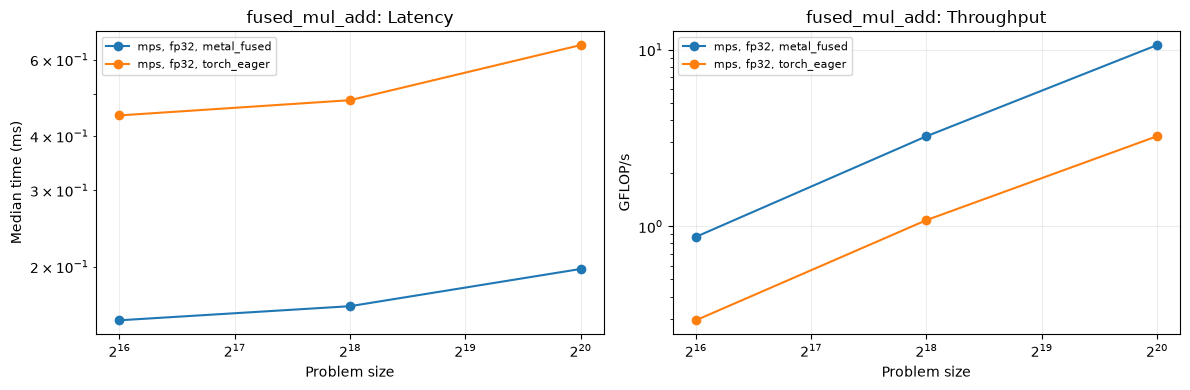

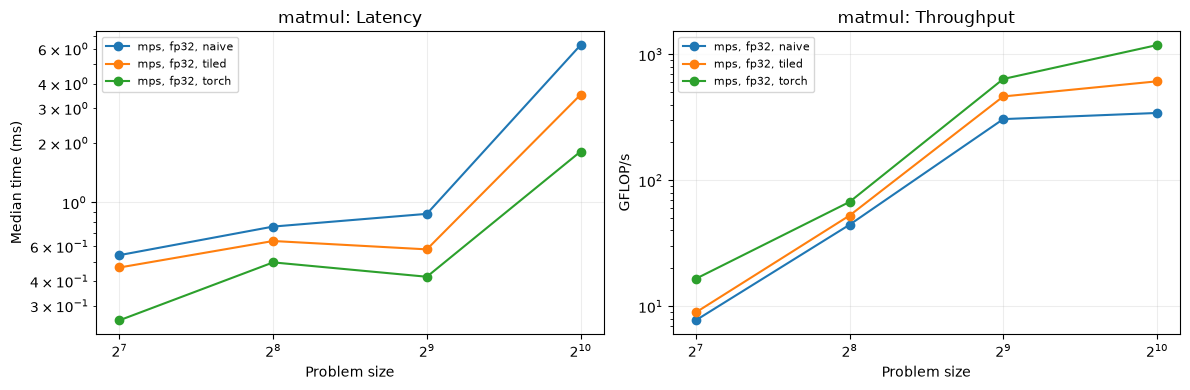

In [2]:
# Latency and throughput versus problem size. Matmul size is N for NxN @ NxN;
# elementwise size is the number of elements.
for operation, group in df.groupby('operation'):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for (device, precision, variant), series in group.groupby(['device', 'precision', 'variant']):
        series = series.sort_values('size')
        label = f'{device}, {precision}, {variant}'
        axes[0].plot(series['size'], series['median_ms'], marker='o', label=label)
        axes[1].plot(series['size'], series['gflops'], marker='o', label=label)
    for ax, ylabel, title in [(axes[0], 'Median time (ms)', 'Latency'),
                              (axes[1], 'GFLOP/s', 'Throughput')]:
        ax.set_xscale('log', base=2)
        ax.set_yscale('log')
        ax.set_xlabel('Problem size')
        ax.set_ylabel(ylabel)
        ax.set_title(f'{operation}: {title}')
        ax.grid(True, which='major', alpha=.22)
        ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()

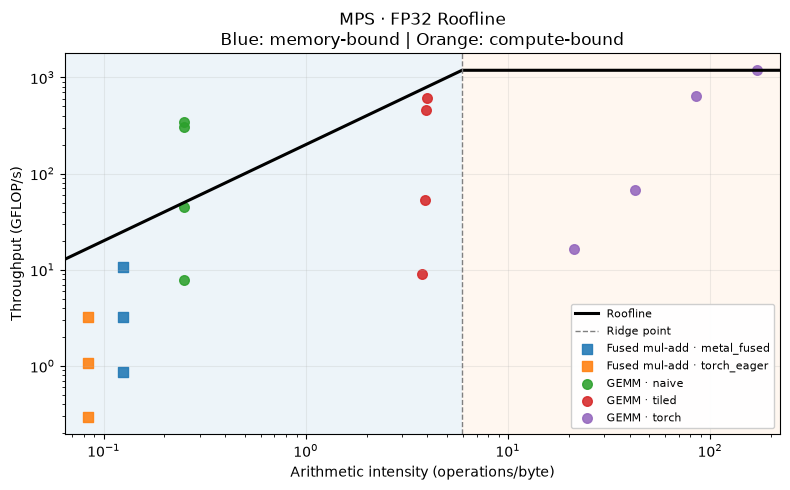

In [3]:
# Plot each device and precision separately. The custom comparisons share the
# MPS device with PyTorch, so each variant appears on the same axes.
MEMORY_BANDWIDTH_GB_S = 200.0
COMPUTE_PEAK_OVERRIDE_GFLOPS = {
    # Optional sourced overrides, e.g. ('mps', 'fp32'): 10000.0
}

roof_data = df[df['operation'].isin(['matmul', 'fused_mul_add'])]
for (device, precision), group in roof_data.groupby(['device', 'precision']):
    gemm = group[group['operation'] == 'matmul']
    if gemm.empty:
        continue

    compute_roof = COMPUTE_PEAK_OVERRIDE_GFLOPS.get(
        (device, precision), gemm['gflops'].max())
    knee = compute_roof / MEMORY_BANDWIDTH_GB_S
    data_min = group['arithmetic_intensity'].min()
    data_max = group['arithmetic_intensity'].max()
    x_min = min(data_min / 1.3, knee / 1.5)
    x_max = data_max * 1.3
    xs = pd.Series(sorted({x_min, knee, x_max}))
    roof = (MEMORY_BANDWIDTH_GB_S * xs).clip(upper=compute_roof)

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(max(group['gflops'].min() / 1.5, 1e-3), compute_roof * 1.5)
    ax.axvspan(x_min, knee, color='tab:blue', alpha=.08, linewidth=0)
    ax.axvspan(knee, x_max, color='tab:orange', alpha=.06, linewidth=0)
    ax.plot(xs, roof, color='black', linewidth=2.2, label='Roofline')
    ax.axvline(knee, color='gray', linestyle='--', linewidth=1, label='Ridge point')

    markers = {'matmul': 'o', 'fused_mul_add': 's'}
    names = {'matmul': 'GEMM', 'fused_mul_add': 'Fused mul-add'}
    for (operation, variant), points in group.groupby(['operation', 'variant']):
        ax.scatter(points['arithmetic_intensity'], points['gflops'],
                   marker=markers[operation], s=48,
                   label=f'{names[operation]} · {variant}', alpha=.88)

    ax.set_title(f'{device.upper()} · {precision.upper()} Roofline\nBlue: memory-bound | Orange: compute-bound')
    ax.set_xlabel('Arithmetic intensity (operations/byte)')
    ax.set_ylabel('Throughput (GFLOP/s)')
    ax.grid(True, which='major', alpha=.22)
    ax.legend(loc='lower right', fontsize=8, framealpha=.95)
    plt.tight_layout()
    plt.show()

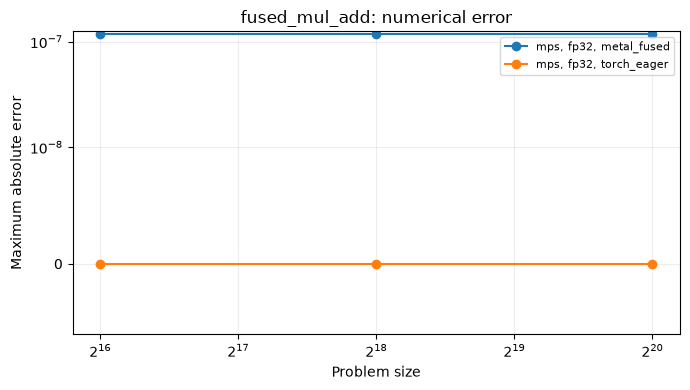

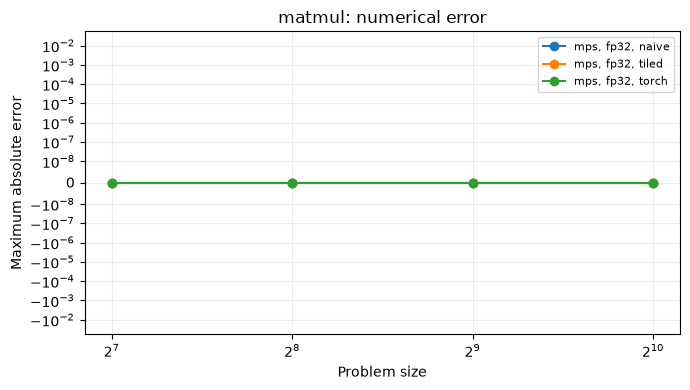

In [4]:
# Error relative to the FP32 reference. Variant labels distinguish the custom kernels.
for operation, group in df.groupby('operation'):
    fig, ax = plt.subplots(figsize=(7, 4))
    for (device, precision, variant), series in group.groupby(['device', 'precision', 'variant']):
        series = series.sort_values('size')
        ax.plot(series['size'], series['max_abs_error'], marker='o',
                label=f'{device}, {precision}, {variant}')
    ax.set_xscale('log', base=2)
    ax.set_yscale('symlog', linthresh=1e-8)
    ax.set_xlabel('Problem size')
    ax.set_ylabel('Maximum absolute error')
    ax.set_title(f'{operation}: numerical error')
    ax.grid(True, which='major', alpha=.22)
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()